# Step Evenness Score — unsupervised (0–100) — **3-class surfaces**

Assigns each step an **evenness score from 0 (very uneven/rough) to 100 (very even/smooth)** with
**no surface labels** anywhere. It combines a set of per-step *irregularity* features — foot-tilt
range, centre-of-pressure wander, pressure jitter, gyro wobble, and step-to-step consistency —
into one index, calibrated so 50 = a typical step.

This is a *scoring model*, not a classifier: it fits a robust scaler on your recordings, then can
score any new step. It never sees a surface tag. (Section 7 optionally checks the score against
surface tags **only to validate** it — labels are never used to build the score.)

In [47]:
import os, glob, json, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import norm

# ---- paths ----
# Recordings to FIT the evenness scale on. Set this to wherever your recordings live.
# Relative paths resolve from the notebook's working directory (print(os.getcwd()) to check).
# For certainty, use an absolute path, e.g.:
#   RAW_GLOB = r'C:\\Users\\Sam\\WalkSensePlace\\Individual Users\\**\\*.csv'
REPO_ROOT = os.getcwd()
for _ in range(6):
    if os.path.isdir(os.path.join(REPO_ROOT, 'Individual Users')): break
    _up = os.path.dirname(REPO_ROOT)
    if _up == REPO_ROOT: break
    REPO_ROOT = _up
print('REPO_ROOT =', REPO_ROOT)
RAW_GLOB   = os.path.join(REPO_ROOT, 'Individual Users', '**', '*.csv')
CHARTS_DIR = os.path.join(REPO_ROOT, 'Charts_Graphs'); os.makedirs(CHARTS_DIR, exist_ok=True)

# ---- step segmentation --------------------------------------------------------
# 'peaks'  : windows between peaks of the 12-sensor pressure SUM. Original behaviour.
# 'events' : windows from one true initial contact to the next, read from
#            Ground Contact/<user>/REC_*_groundcontact.csv.
#
# The pressure-sum peak is not initial contact. Measured against the event files on three
# recordings, the heel-sum peak lags contact by a median 112-128 ms, which puts initial
# contact roughly 12% of a cycle BEFORE the window starts. Three evenness features are
# anchored to the start of the window and are affected directly:
#   loading_rate = max(diff(tot))/mean   - the loading ramp may fall in the previous window
#   impact       = max of the first THIRD of accel magnitude / median
#   stance_dur   = fraction of the window with tot above half its mean
# With events the window starts at contact, so all three measure the phase they name.
#
# IMPORTANT: the fitted scale is not transferable between the two settings. The scaler
# records which segmentation produced it; re-fit after changing this, and do not score
# new recordings with a scaler fitted under the other setting.
SEGMENTATION    = 'events'
GC_DIR          = os.path.join(REPO_ROOT, 'Ground Contact')   # <user>/REC_*_groundcontact.csv
EVENTS_REQUIRED = True   # with 'events', skip recordings that have no event file rather
                         # than mixing two segmentations in one fitted scale


# ---- signal / layout ----
# ---- window length limits -----------------------------------------------------
# A window shorter than MIN_DP or longer than MAX_DP samples is not treated as a step.
#
# These MUST match the prediction notebooks, or the two pipelines count different steps.
# The classifier notebooks use MIN_DP = 5 and NO upper limit, so with 15/150 this notebook
# reported 22 fewer steps: it dropped windows longer than 2.4 s that the classifiers kept.
# MATCH_CLASSIFIER_WINDOWS = True reproduces the classifier set exactly.
#
# On the merits a window over ~2.4 s is not a gait cycle (a stride is about 1 s): it is a
# pause, a stumble, or a missed contact event, and its 'step-to-step' features are
# meaningless. Capping it is the better choice - but then the CLASSIFIERS should cap it
# too, and their published counts would change. Set to True for now so every count in the
# paper agrees; the audit below prints how many steps the choice is worth.
MATCH_CLASSIFIER_WINDOWS = True
FS = 62.5
MIN_DP = 5 if MATCH_CLASSIFIER_WINDOWS else 15
MAX_DP = 10**9 if MATCH_CLASSIFIER_WINDOWS else 150
print(f'window limits: MIN_DP={MIN_DP}'
      + ('  MAX_DP=none (matching the classifier notebooks)' if MATCH_CLASSIFIER_WINDOWS
         else f'  MAX_DP={MAX_DP} ({MAX_DP/FS:.1f} s)'))
ALL_SENSORS = [f'pressure_{i:02d}' for i in range(1, 13)]
BASE_COLS   = set(['sole_id','timestamp','accel_x','accel_y','accel_z','gyro_x','gyro_y','gyro_z',
                   'magn_x','magn_y','magn_z','corrupt'] + ALL_SENSORS)

# ---- evenness feature set (every one: higher = MORE uneven) ----
WITHIN_STEP = ['orient_range_a','orient_range_b','cop_wander','press_jitter','gyro_std']
STEP_TO_STEP = ['stance_dur','loading_rate','impact','tiltA','tiltB']    # -> rolling 3-step std
EVENNESS_FEATURES = WITHIN_STEP + [f'{c}_roll3_std' for c in STEP_TO_STEP]
# ---- a dead feature, in BOTH segmentations -----------------------------------
# stance_dur = (totw > 0.5*totw.mean()).mean() is EXACTLY 1.0 for every step checked,
# because the 12-sensor sum never drops below half its own window mean inside a stride -
# the pads have a large resting offset, so the sum never approaches zero. stance_dur
# therefore carries no information and stance_dur_roll3_std is identically 0, which left
# the evenness index U as the mean of NINE live z-scores plus one constant.
#
# Data collection is complete and 'events' is the settled segmentation, so the dead
# feature is now DROPPED rather than carried: it only shifted U by a constant, and that
# constant differed between segmentations. The cell below reports which features are
# actually dead in YOUR full data, so this is checked rather than assumed.
#
# With events there is a real alternative: USE_MEASURED_STANCE replaces stance_dur with
# the measured stance fraction (toe_off - heel_strike) / cycle, about 0.57 and varying
# step to step, so stance_dur_roll3_std becomes a live step-to-step feature again. It is
# unavailable under 'peaks', so turning it on makes the two settings non-comparable by
# feature set as well as by scale. Off by default; turn it on only if you want stance
# variability in the index, and re-fit.
DROP_DEAD_FEATURES  = True    # drop features with no variance from EVENNESS_FEATURES
USE_MEASURED_STANCE = False   # events only: real stance fraction in place of stance_dur
print('evenness features:', EVENNESS_FEATURES)
SURF_COLORS = {'grass':'#4CAF50','loose':'#8D6E63','paved':'#607D8B',
               'soft':'#4CAF50','hard':'#607D8B'}

# ---- output naming ----
# This is the 3-class variant; the step gate below keeps a different step set from
# the 4-class notebook, so every artefact here is suffixed. Without this the run
# would overwrite evenness_scaler.json, which predict_walks.py loads.
SURF_SCHEME = '3class'
SUF = f'_{SURF_SCHEME}_{SEGMENTATION}'   # outputs carry BOTH the surface scheme and
                                         # the segmentation, so an events-fitted scale
                                         # can never overwrite a peaks-fitted one

# ---- surface + transition tags (must match the prediction models) ----
# 3-class scheme: grass / loose / paved, matching the 3-class prediction model. Every
# paved material - continuous (concrete/asphalt/brick/exposed aggregate) and modular
# (cobblestone/uneven brick) - collapses into one 'paved' class. The unsupervised score
# is unaffected by this; it governs the transition GATE (below) and the optional
# surface-validation sections. NOTE the gate consequence: a step crossing a
# brick -> cobblestone boundary straddled two classes under the 4-class scheme and was
# dropped; here both sides read 'paved', so the step is KEPT. Expect a slightly larger
# step set than the 4-class run, and therefore a slightly different fitted scaler.
SMAP = {
    'grass': 'grass',
    'dirt': 'loose', 'compact ground': 'loose', 'compacted ground': 'loose',
    'concrete': 'paved', 'asphalt': 'paved', 'exposed aggregate': 'paved', 'brick': 'paved', 'wood': 'paved'
}
# transition/wait markers open an EXCLUDED region; any step touching it is dropped (same as
# the prediction models' step gate, option (a): transition/wait exclusion).
EXCLUDE_TAGS = {'transition','wait'}
# full gate (option b): also drop steps that STRADDLE two surfaces or are only partially
# inside one labelled surface -- matching the prediction models' step gate exactly.
EXCLUDE_TRANSITION_STEPS    = True
TRANSITION_MIN_LABELED_FRAC = 0.80   # a kept step must be >=80% inside ONE labelled surface
EXCLUDE_LABEL = '__exclude__'

REPO_ROOT = c:\Users\Sam\WalkSensePlace
window limits: MIN_DP=5  MAX_DP=none (matching the classifier notebooks)
evenness features: ['orient_range_a', 'orient_range_b', 'cop_wander', 'press_jitter', 'gyro_std', 'stance_dur_roll3_std', 'loading_rate_roll3_std', 'impact_roll3_std', 'tiltA_roll3_std', 'tiltB_roll3_std']


## 1. Per-step irregularity extractor (label-free)

Detects steps from total-pressure peaks and computes each irregularity feature per step. No surface markers are read.

In [48]:
def find_steps(tot):
    mx = np.nanmax(tot) if np.nanmax(tot) > 0 else 1.0
    pk, _ = find_peaks(tot, distance=25, prominence=mx*0.15); return pk

# ---- vendor contact events ----------------------------------------------------
# Ground Contact/<user>/<stem>_groundcontact.csv, semicolon separated, columns
# sole_id;heel_strike;toe_off in Unix ms. The user folder is taken from the recording's
# own path, so this works for any 'Individual Users/<user>/REC_*.csv' layout.
def contact_events(rec_path, sole_id):
    user = os.path.basename(os.path.dirname(rec_path))
    stem = os.path.splitext(os.path.basename(rec_path))[0]
    p = os.path.join(GC_DIR, user, f'{stem}_groundcontact.csv')
    if not os.path.exists(p):
        return None
    try:
        e = pd.read_csv(p, sep=';')
    except Exception:
        return None
    e = e[pd.to_numeric(e['sole_id'], errors='coerce') == float(sole_id)].sort_values('heel_strike')
    if len(e) < 2:
        return None
    return (e['heel_strike'].to_numpy(float), e['toe_off'].to_numpy(float))


_EVENT_SKIPS = []


def event_windows(ts, events):
    """Event times -> (starts, ends) row indices, one window per gait cycle.

    Returns empty arrays when no usable window exists, and records why. It does NOT fall
    back to peak segmentation: mixing the two inside one fitted scale is worse than
    dropping a sole.
    """
    empty = (np.empty(0, dtype=int), np.empty(0, dtype=int))
    hs, to = events
    ts = np.asarray(ts, float)
    if len(ts) == 0 or len(hs) == 0:
        _EVENT_SKIPS.append('no samples or no events'); return empty
    keep = (hs >= ts[0]) & (hs <= ts[-1])
    hs = hs[keep]
    if len(hs) < 2:
        _EVENT_SKIPS.append('fewer than 2 events inside this sole\'s rows'); return empty
    b = np.searchsorted(ts, hs)
    _, first = np.unique(b, return_index=True)
    b = b[np.sort(first)]
    if len(b) < 2:
        _EVENT_SKIPS.append('all events collapsed onto one sample'); return empty
    return b[:-1], b[1:]


def step_windows(tot, ts=None, events=None):
    """The one place window boundaries are decided, for both segmentation settings."""
    if SEGMENTATION == 'events' and events is not None and ts is not None:
        return event_windows(ts, events)
    pk = find_steps(tot)
    return pk[:-1], pk[1:]


def measured_stance_frac(ts, a, b, events):
    """(toe_off - heel_strike) / cycle for the window [a, b), or nan.

    Uses the first toe-off at or after the window's own heel strike, so a missing or
    out-of-order toe-off gives nan for that step instead of a wrong value."""
    if events is None:
        return float('nan')
    hs, to = events
    t0, t1 = float(ts[a]), float(ts[b - 1])
    cyc = t1 - t0
    if cyc <= 0:
        return float('nan')
    k = np.searchsorted(np.asarray(to, float), t0)
    if k >= len(to):
        return float('nan')
    st = float(to[k]) - t0
    return st / cyc if 0 < st <= cyc else float('nan')


def extract_steps(df, rec, foot, events=None):
    """Per-step irregularity features for one sole's dataframe. Returns a DataFrame."""
    df = df.reset_index(drop=True)
    if len(df) < MIN_DP: return pd.DataFrame()
    P   = df[ALL_SENSORS].apply(pd.to_numeric, errors='coerce').fillna(0).values
    tot = P.sum(1)
    ax = pd.to_numeric(df['accel_x'],errors='coerce').fillna(0).values
    ay = pd.to_numeric(df['accel_y'],errors='coerce').fillna(0).values
    az = pd.to_numeric(df['accel_z'],errors='coerce').fillna(0).values
    G  = df[['gyro_x','gyro_y','gyro_z']].apply(pd.to_numeric,errors='coerce').fillna(0).values
    Gc = G - np.median(G, 0)
    amag = np.sqrt(ax**2+ay**2+az**2); gmag = np.sqrt((Gc**2).sum(1))
    tA = np.degrees(np.arctan2(ax, np.hypot(ay, az)))
    tB = np.degrees(np.arctan2(az, np.hypot(ax, ay)))
    ts = pd.to_numeric(df['timestamp'], errors='coerce').values if 'timestamp' in df.columns else np.arange(len(df))
    starts, ends = step_windows(tot, ts, events)
    recs = []; order = 0
    for i in range(len(starts)):
        a, b = int(starts[i]), int(ends[i]); n = b-a
        if n < MIN_DP or n > MAX_DP: continue
        Pw = P[a:b]; totw = tot[a:b]; sc = totw.mean()+1e-9; wam = amag[a:b]; wgm = gmag[a:b]
        Qn = Pw/(Pw.sum(1, keepdims=True)+1e-9); t = int(np.argmin(wgm))
        recs.append(dict(
            rec=rec, foot=foot, order=order, t_ms=float(ts[(a+b)//2]),
            orient_range_a = float(tA[a:b].max()-tA[a:b].min()),
            orient_range_b = float(tB[a:b].max()-tB[a:b].min()),
            cop_wander     = float(np.mean(np.abs(np.diff(Qn, axis=0)).sum(1))) if n > 1 else 0.0,
            press_jitter   = float(np.mean(np.std(np.diff(Pw, n=2, axis=0), axis=0))/sc) if n > 2 else 0.0,
            gyro_std       = float(np.mean([np.std(Gc[a:b, k]) for k in range(3)])),
            stance_dur   = (measured_stance_frac(ts, a, b, events)
                            if (USE_MEASURED_STANCE and SEGMENTATION == 'events')
                            else float((totw > 0.5*sc).mean())),
            loading_rate = float(np.max(np.diff(totw))/sc),
            impact       = float(wam[:max(1, n//3)].max()/(np.median(wam)+1e-9)),
            tiltA = float(tA[a:b][t]), tiltB = float(tB[a:b][t])))
        order += 1
    return pd.DataFrame(recs)
print(f'extractor defined; SEGMENTATION={SEGMENTATION}')

extractor defined; SEGMENTATION=events


## 2. Build steps from the recordings

Every step from every recording — no labels required. Then add the step-to-step consistency features (rolling 3-step std within each recording+foot).

In [49]:
# ---- FULL step gate (option b): ports label_surface_segments + step_surface_label ----
# Row labelling: each surface/transition 'x' marker opens a region running to the NEXT marker.
# transition/wait open an EXCLUDED region. Then a step is DROPPED if its window (a) touches an
# excluded row, (b) straddles >1 surface, or (c) is <TRANSITION_MIN_LABELED_FRAC labelled.
def _row_surface_labels(df):
    d = df.sort_values('timestamp').reset_index(drop=True) if 'timestamp' in df.columns else df.reset_index(drop=True)
    events = []
    for c in d.columns:
        cl = c.strip().lower()
        if cl in BASE_COLS: continue
        if cl in EXCLUDE_TAGS: lab = EXCLUDE_LABEL
        elif cl in SMAP:        lab = SMAP[cl]
        else: continue
        for idx in d.index[d[c].astype(str).str.strip() == 'x']:
            events.append((int(idx), lab))
    if not events: return None
    events.sort(key=lambda e: e[0])
    surf = np.array([None]*len(d), dtype=object)
    for k,(i0,lab) in enumerate(events):
        i1 = events[k+1][0] if k+1 < len(events) else len(d)
        surf[i0:i1] = lab
    return surf

def _step_kept(surf_slice):
    """(kept?, surface) for this step window.

    The surface is the single labelled class inside the window, or None when the window is
    unlabelled. Returning it here is what keeps the gate and the by-surface sections in
    agreement: section 7 onward uses THIS label instead of re-deriving one."""
    ws = surf_slice
    if any(v == EXCLUDE_LABEL for v in ws): return False, None    # touches transition/wait
    lab = [v for v in ws if v is not None]                        # labelled rows only
    if EXCLUDE_TRANSITION_STEPS:
        if len(set(lab)) > 1: return False, None                  # straddles two surfaces
        if len(lab) < TRANSITION_MIN_LABELED_FRAC * len(ws): return False, None  # partial / edge
    return True, (lab[0] if len(set(lab)) == 1 else None)

_GATE_STATS = {'dropped':0,'kept':0}
_NO_EVENT_FILES = []
# per-recording accounting, so a low total can be traced to the stage that caused it
_AUDIT = []      # one row per recording: where its steps went
_SKIPPED = []    # (recording, reason) for recordings that contributed nothing
files = sorted(glob.glob(RAW_GLOB, recursive=True))
print(f'cwd = {os.getcwd()}')
print(f'RAW_GLOB = {RAW_GLOB!r}  ->  {len(files)} file(s) matched')
if not files:
    files = sorted(glob.glob(os.path.join('**','REC_*.csv'), recursive=True))
    print(f'fallback search for REC_*.csv -> {len(files)} file(s)')
if not files:
    raise FileNotFoundError(
        f"No CSVs found. RAW_GLOB={RAW_GLOB!r} matched nothing from cwd {os.getcwd()!r}. "
        r"Set RAW_GLOB in the config cell to your recordings, e.g. "
        r"r'C:\\Users\\Sam\\WalkSensePlace\\Individual Users\\**\\*.csv'")

parts = []
for f in files:
    rec = os.path.basename(f)
    if rec.endswith('_groundcontact.csv') or '_GPS' in rec:
        continue                                   # not a recording
    try: raw = pd.read_csv(f, low_memory=False)
    except Exception as _e:
        _SKIPPED.append((rec, f'unreadable: {type(_e).__name__}')); continue
    if 'sole_id' not in raw.columns:
        _SKIPPED.append((rec, 'no sole_id column')); continue
    soles = list(raw['sole_id'].dropna().unique())
    pairs = [(s, ('right' if str(s) in ('1','1.0') else 'left' if str(s) in ('2','2.0') else f'sole{s}')) for s in soles]
    if SEGMENTATION == 'events' and EVENTS_REQUIRED:
        if not any(contact_events(f, s) for s, _ in (pairs or [(1, None), (2, None)])):
            _NO_EVENT_FILES.append(rec)
            _SKIPPED.append((rec, f'no contact-event file in {GC_DIR}'))
            continue
    _a = dict(rec=rec, rows=len(raw), soles=len(pairs), windows=0, too_short=0, too_long=0,
              gated=0, kept=0, labelled=False, long_windows=0, long_kept=0)
    for sole, foot in (pairs or [(1,'right'),(2,'left')]):
        sub = raw[raw['sole_id'] == sole].reset_index(drop=True)
        _ev = contact_events(f, sole) if SEGMENTATION == 'events' else None
        # account for every window this sole produced, before any gate
        _tot_dbg = sub[ALL_SENSORS].apply(pd.to_numeric, errors='coerce').fillna(0).values.sum(1)
        _ts_dbg = (pd.to_numeric(sub['timestamp'], errors='coerce').values
                   if 'timestamp' in sub.columns else np.arange(len(sub)))
        _s_dbg, _e_dbg = step_windows(_tot_dbg, _ts_dbg, _ev)
        _n_dbg = np.asarray(_e_dbg, int) - np.asarray(_s_dbg, int)
        _a['windows'] += len(_n_dbg)
        _a['too_short'] += int((_n_dbg < MIN_DP).sum()); _a['too_long'] += int((_n_dbg > MAX_DP).sum())
        # what a 2.4 s cap would cost, whatever MAX_DP is set to: count the long windows
        # that DO pass the surface gate, i.e. the steps the two pipelines disagree about
        _long = np.where(_n_dbg > 150)[0]
        if len(_long):
            _sv = _row_surface_labels(sub)
            for _j in _long:
                _a['long_windows'] = _a.get('long_windows', 0) + 1
                if _sv is None or _step_kept(list(_sv[int(_s_dbg[_j]):int(_e_dbg[_j])]))[0]:
                    _a['long_kept'] = _a.get('long_kept', 0) + 1
        st = extract_steps(sub, rec, foot, events=_ev)
        if not len(st): continue
        # --- FULL step GATE (option b): transition + straddle + partial ---
        surf = _row_surface_labels(sub)
        if surf is not None:
            P = sub[ALL_SENSORS].apply(pd.to_numeric, errors='coerce').fillna(0).values
            tot = P.sum(1)
            _ts = pd.to_numeric(sub['timestamp'], errors='coerce').values \
                  if 'timestamp' in sub.columns else np.arange(len(sub))
            _st_, _en_ = step_windows(tot, _ts, _ev)   # SAME windows as extract_steps
            keep_order = []; _surf_of = {}; oi = 0
            for i in range(len(_st_)):
                a, b = int(_st_[i]), int(_en_[i]); n = b-a
                if n < MIN_DP or n > MAX_DP: continue   # mirror extract_steps' filter so 'order' aligns
                _ok, _lab = _step_kept(list(surf[a:b]))
                if _ok:
                    keep_order.append(oi); _surf_of[oi] = _lab
                oi += 1
            before = len(st)
            st = st[st['order'].isin(keep_order)].reset_index(drop=True)
            st['surface'] = st['order'].map(_surf_of)   # the gate's own label, carried forward
            _GATE_STATS['dropped'] += before - len(st); _GATE_STATS['kept'] += len(st)
            _a['gated'] += before - len(st); _a['labelled'] = True
        else:
            _GATE_STATS['kept'] += len(st)   # no labels in this recording -> keep all (unsupervised)
            st['surface'] = None             # no tags: usable for the fit, not by surface
        _a['kept'] += len(st)
        if len(st): parts.append(st)
    _AUDIT.append(_a)
    if _a['kept'] == 0:
        _SKIPPED.append((rec, 'produced 0 steps'))
if not parts:
    raise ValueError(f'Matched {len(files)} CSV(s) but extracted 0 steps. Check for sole_id, '
                     'pressure_01..12, accel_x/y/z, gyro_x/y/z columns and enough samples per step.')

steps = pd.concat(parts, ignore_index=True).sort_values(['rec','foot','order']).reset_index(drop=True)
for c in STEP_TO_STEP:
    steps[f'{c}_roll3_std'] = steps.groupby(['rec','foot'])[c].transform(
        lambda x: x.rolling(3, min_periods=1).std().fillna(0))
print(f"full step gate (transition/wait + surface-straddle + partial): kept {_GATE_STATS['kept']} steps, dropped {_GATE_STATS['dropped']}")
print(f'segmentation = {SEGMENTATION}'
      + (f'  (events from {GC_DIR})' if SEGMENTATION == 'events' else '  (pressure-sum peaks)'))
if SEGMENTATION == 'events':
    if _NO_EVENT_FILES:
        print(f'  skipped {len(_NO_EVENT_FILES)} recording(s) with no event file: '
              f'{sorted(_NO_EVENT_FILES)[:6]}{" ..." if len(_NO_EVENT_FILES) > 6 else ""}')
    if _EVENT_SKIPS:
        from collections import Counter as _C
        print('  soles yielding no windows: '
              + '; '.join(f'{r} x{n}' for r, n in _C(_EVENT_SKIPS).items()))
_dead = [c for c in EVENNESS_FEATURES if steps[c].nunique() <= 1]
if _dead:
    print(f'[dead features] no variance in this data: {_dead}'
          + ('  -> dropped' if DROP_DEAD_FEATURES else
             '  -> KEPT (they add a constant to U, no variation). '
             'Set DROP_DEAD_FEATURES=True to drop them.'))
    if DROP_DEAD_FEATURES:
        EVENNESS_FEATURES = [c for c in EVENNESS_FEATURES if c not in _dead]
print(f'{len(steps)} steps from {steps.rec.nunique()} recordings')

# ---- where did the steps go? (a low total is traced to a stage, not guessed at) ----
AUDIT = pd.DataFrame(_AUDIT)
if len(AUDIT):
    _w, _k = int(AUDIT.windows.sum()), int(AUDIT.kept.sum())
    print(f'\nstep accounting over {len(AUDIT)} recording(s) that were read:')
    print(f'  {_w:6d} windows cut by segmentation')
    print(f'  -{int(AUDIT.too_short.sum()):5d} shorter than MIN_DP={MIN_DP} samples'
          f'  ({MIN_DP/FS*1000:.0f} ms)')
    if MAX_DP < 10**6:
        print(f'  -{int(AUDIT.too_long.sum()):5d} longer than MAX_DP={MAX_DP} samples'
              f'  ({MAX_DP/FS:.1f} s)')
    else:
        print('  -    0 rejected for length (no upper limit set)')
    print(f'  -{int(AUDIT.gated.sum()):5d} dropped by the surface gate')
    _lw, _lk = int(AUDIT.long_windows.sum()), int(AUDIT.long_kept.sum())
    if _lw:
        print(f'  ({_lw} window(s) ran longer than 2.4 s - not a gait cycle; {_lk} of them '
              f'pass the surface gate.'
              + ('  Those ' + str(_lk) + ' ARE included here, matching the classifier '
                 'notebooks.' if MATCH_CLASSIFIER_WINDOWS else
                 '  Those ' + str(_lk) + ' are EXCLUDED here but kept by the classifier '
                 'notebooks, so this notebook reports ' + str(_lk) + ' fewer steps.'))
    print(f'  ={_k:6d} kept'
          + (f'   ({100*_k/_w:.1f}% of windows)' if _w else ''))
    _unl = AUDIT[~AUDIT.labelled]
    if len(_unl):
        print(f'  note: {len(_unl)} recording(s) had NO surface tags, so every step was kept '
              f'({int(_unl.kept.sum())} steps). Fine for the unsupervised fit; they cannot '
              'appear in the by-surface sections.')
print(f'\nfiles matched: {len(files)} | recordings read: {len(AUDIT)} | '
      f'contributing steps: {steps.rec.nunique()}')
if _SKIPPED:
    from collections import Counter as _C2
    print(f'{len(_SKIPPED)} recording(s) contributed NOTHING:')
    for _reason, _n in _C2(r for _, r in _SKIPPED).most_common():
        _eg = [rc for rc, rr in _SKIPPED if rr == _reason][:4]
        print(f'   {_n:3d} x {_reason}   e.g. {_eg}')
    print('   -> if these are real recordings, this is where the missing steps are. '
          'A missing contact-event file is the usual cause: check that Ground Contact/<user>/ '
          'holds <REC>_groundcontact.csv for every recording, with the SAME user folder name '
          'as under Individual Users.')
    _zero = AUDIT[AUDIT.kept == 0] if len(AUDIT) else AUDIT
    if len(_zero):
        print('   recordings that were READ but produced 0 steps, and why:')
        for _, _r in _zero.iterrows():
            _why = ('no windows cut (too few contact events in range)' if _r.windows == 0 else
                    f'all {int(_r.windows)} window(s) rejected: '
                    f'{int(_r.too_short)} too short, {int(_r.too_long)} too long, '
                    f'{int(_r.gated)} gated')
            print(f'     {_r.rec}: {_r.rows} rows, {_r.soles} sole(s) - {_why}')
print('per-recording detail in AUDIT (sort_values(\'kept\') to see the thinnest).')
_sc = steps['surface'].value_counts(dropna=False)
print('\nsteps by surface (the gate\'s own labels, used by every later section):')
for _k, _v in _sc.items():
    print(f'   {str(_k) if _k == _k and _k is not None else "unlabelled":12s} {_v:6d}'
          f'   {100*_v/len(steps):5.1f}%')
print(f'   {"TOTAL":12s} {len(steps):6d}')
print(steps[EVENNESS_FEATURES].describe().round(3).T[['mean','std','min','max']].to_string())

cwd = c:\Users\Sam\WalkSensePlace\notebooks
RAW_GLOB = 'c:\\Users\\Sam\\WalkSensePlace\\Individual Users\\**\\*.csv'  ->  78 file(s) matched
full step gate (transition/wait + surface-straddle + partial): kept 21213 steps, dropped 2828
segmentation = events  (events from c:\Users\Sam\WalkSensePlace\Ground Contact)
21213 steps from 77 recordings

step accounting over 78 recording(s) that were read:
   24041 windows cut by segmentation
  -    0 shorter than MIN_DP=5 samples  (80 ms)
  -    0 rejected for length (no upper limit set)
  - 2828 dropped by the surface gate
  (42 window(s) ran longer than 2.4 s - not a gait cycle; 22 of them pass the surface gate.  Those 22 ARE included here, matching the classifier notebooks.
  = 21213 kept   (88.2% of windows)

files matched: 78 | recordings read: 78 | contributing steps: 77
1 recording(s) contributed NOTHING:
     1 x produced 0 steps   e.g. ['REC_20261006_215404.csv']
   -> if these are real recordings, this is where the missing steps are. 

## 3. Fit the scale and compute the 0–100 evenness score

Each feature is **robustly standardised** (median / IQR, clipped) so no single feature or outlier
dominates, then averaged into an *unevenness index* U (higher = rougher). U is standardised and
passed through the normal CDF so the score is calibrated and transferable: **50 = a typical step,
higher = smoother/more even.** The fitted numbers are saved so any new step can be scored the same way.

In [50]:
def robust_center_scale(x):
    med = float(np.median(x)); iqr = float(np.subtract(*np.percentile(x, [75, 25])))
    if iqr <= 0: iqr = float(np.std(x)) or 1.0
    return med, iqr

# fit per-feature center/scale
feat_cs = {c: robust_center_scale(steps[c].values) for c in EVENNESS_FEATURES}
def _z(col, v): m, s = feat_cs[col]; return np.clip((v - m)/(s + 1e-9), -4, 4)

Z = np.column_stack([_z(c, steps[c].values) for c in EVENNESS_FEATURES])
U = Z.mean(1)                                   # unevenness index (higher = rougher)
U_med, U_iqr = robust_center_scale(U)
steps['evenness'] = np.clip(100*norm.cdf(-(U - U_med)/(U_iqr + 1e-9)), 0, 100)

SCALER = {'segmentation': SEGMENTATION,
          'features': EVENNESS_FEATURES, 'feat_center_scale': feat_cs,
          'U_center': U_med, 'U_scale': U_iqr}
json.dump(SCALER, open(os.path.join(CHARTS_DIR, f'evenness_scaler{SUF}.json'), 'w'), indent=1)
steps[['rec','foot','order','t_ms','evenness']+EVENNESS_FEATURES].to_csv(
    os.path.join(CHARTS_DIR, f'evenness_scores{SUF}.csv'), index=False)
print('evenness score:  mean %.1f  sd %.1f  min %.1f  max %.1f'
      % (steps.evenness.mean(), steps.evenness.std(), steps.evenness.min(), steps.evenness.max()))
print(steps.evenness.describe(percentiles=[.05,.25,.5,.75,.95]).round(1).to_string())
print(f'\nsaved evenness_scores{SUF}.csv + evenness_scaler{SUF}.json')

evenness score:  mean 47.0  sd 22.7  min 0.0  max 94.7
count    21213.0
mean        47.0
std         22.7
min          0.0
5%           9.1
25%         27.7
50%         50.0
75%         65.8
95%         80.0
max         94.7

saved evenness_scores_3class_events.csv + evenness_scaler_3class_events.json


## 4. Score distribution & what drives it

The spread of scores, and how strongly each feature pushes a step toward *uneven* (correlation of the feature with the unevenness index).

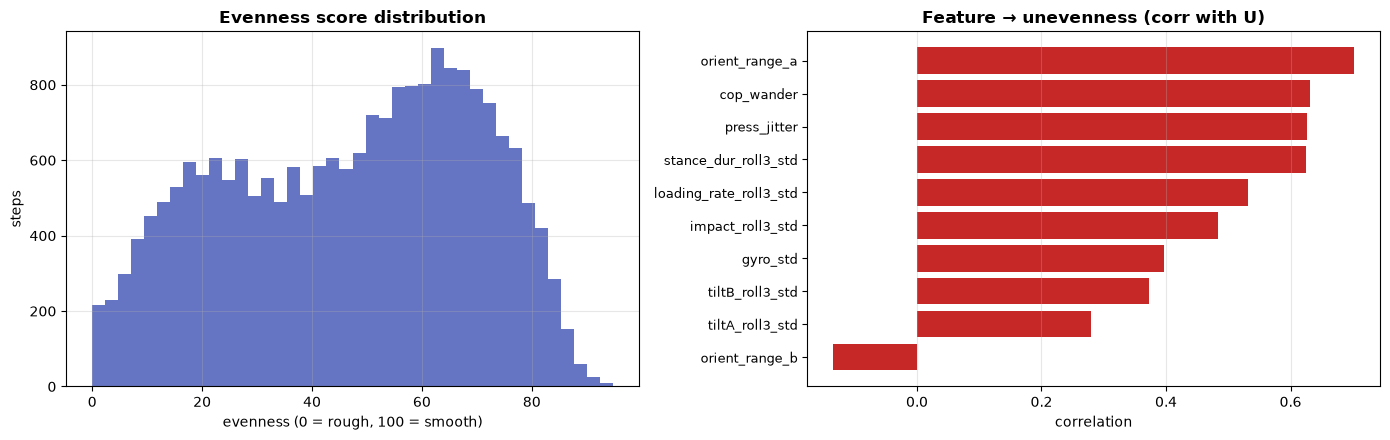

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(steps['evenness'], bins=40, color='#3F51B5', alpha=.8)
ax[0].set_title('Evenness score distribution', fontweight='bold')
ax[0].set_xlabel('evenness (0 = rough, 100 = smooth)'); ax[0].set_ylabel('steps'); ax[0].grid(alpha=.3)
contrib = pd.Series({c: np.corrcoef(_z(c, steps[c].values), U)[0,1] for c in EVENNESS_FEATURES}).sort_values()
ax[1].barh(range(len(contrib)), contrib.values, color='#C62828')
ax[1].set_yticks(range(len(contrib))); ax[1].set_yticklabels(contrib.index, fontsize=9)
ax[1].set_title('Feature → unevenness (corr with U)', fontweight='bold'); ax[1].set_xlabel('correlation'); ax[1].grid(axis='x', alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(CHARTS_DIR, f'evenness_distribution{SUF}.png'), dpi=140, bbox_inches='tight'); plt.show()

## 5. Evenness along a recording

How the score varies step-to-step within one recording+foot — spikes/dips mark rougher/smoother stretches.

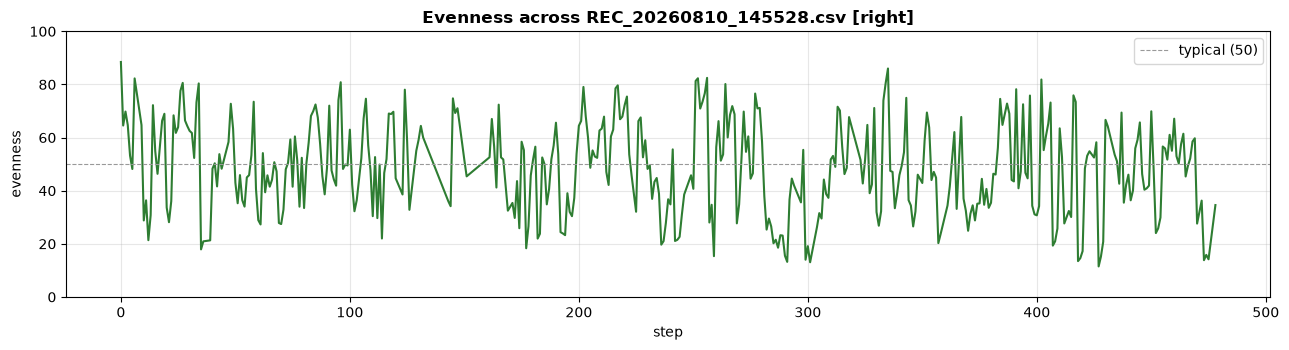

In [52]:
g = steps.groupby(['rec','foot']).size().sort_values(ascending=False)
rec0, foot0 = g.index[0]
seq = steps[(steps.rec==rec0)&(steps.foot==foot0)].sort_values('order')
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(seq['order'], seq['evenness'], color='#2E7D32', lw=1.5)
ax.axhline(50, color='#999', ls='--', lw=.8, label='typical (50)')
ax.set_title(f'Evenness across {rec0} [{foot0}]', fontweight='bold')
ax.set_xlabel('step'); ax.set_ylabel('evenness'); ax.set_ylim(0,100); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(CHARTS_DIR, f'evenness_timeseries{SUF}.png'), dpi=140, bbox_inches='tight'); plt.show()

## 6. Score a new recording

Apply the fitted scaler to any recording (no labels), returning a per-step evenness score with a timestamp (so it can be joined to a GPX for mapping).

In [53]:
def score_recording(csv_path, scaler=SCALER):
    # The scale is only valid for the segmentation it was fitted under: the features are
    # window-anchored, so peaks-fitted centres do not apply to event-cut windows.
    _fit_seg = scaler.get('segmentation')
    if _fit_seg is not None and _fit_seg != SEGMENTATION:
        raise ValueError(f'scaler was fitted with SEGMENTATION={_fit_seg!r} but this '
                         f'notebook is set to {SEGMENTATION!r} - re-fit before scoring')
    raw = pd.read_csv(csv_path, low_memory=False)
    if 'sole_id' not in raw.columns:
        raise ValueError(f"{os.path.basename(csv_path)} has no 'sole_id' column")
    soles = list(raw['sole_id'].dropna().unique())
    pairs = [(s, ('right' if str(s) in ('1','1.0') else 'left' if str(s) in ('2','2.0') else f'sole{s}')) for s in soles]
    parts = []
    for sole, foot in (pairs or [(1,'right'),(2,'left')]):
        _ev = contact_events(csv_path, sole) if SEGMENTATION == 'events' else None
        st = extract_steps(raw[raw['sole_id'] == sole], os.path.basename(csv_path), foot,
                           events=_ev)
        if len(st): parts.append(st)
    if not parts: return pd.DataFrame()
    S = pd.concat(parts, ignore_index=True).sort_values(['foot','order'])
    for c in STEP_TO_STEP:
        S[f'{c}_roll3_std'] = S.groupby('foot')[c].transform(lambda x: x.rolling(3, min_periods=1).std().fillna(0))
    cs = scaler['feat_center_scale']
    Zn = np.column_stack([np.clip((S[c].values - cs[c][0])/(cs[c][1]+1e-9), -4, 4) for c in scaler['features']])
    Un = Zn.mean(1)
    S['evenness'] = np.clip(100*norm.cdf(-(Un - scaler['U_center'])/(scaler['U_scale']+1e-9)), 0, 100)
    return S[['foot','order','t_ms','evenness']]

# demo on the first recording:
_demo = sorted(glob.glob(RAW_GLOB, recursive=True))
if _demo:
    r = score_recording(_demo[0]); print(f'scored {len(r)} steps from {os.path.basename(_demo[0])}')
    print(r['evenness'].describe().round(1).to_string())

scored 151 steps from REC_0811_00000.csv
count    151.0
mean      38.4
std       20.0
min        4.1
25%       21.6
50%       34.6
75%       57.0
max       83.2


## 7. (Optional) Validation against surface tags

Sanity check only — **labels are not used to build the score.** If the recordings carry surface
markers, we expect compliant/irregular ground (grass) to score lower evenness than firm ground.
Surfaces here are the 3-class scheme (grass / loose / paved), so `continuous_paved` and
`modular_paved` are pooled — a cobblestone step and a concrete step both count as `paved`.

In [54]:
# ---- validation against the surface tags -------------------------------------
# These labels are the ones the step gate itself assigned in section 2 (steps['surface']),
# NOT a second pass over the recordings.
#
# The previous version re-extracted every step here and re-derived a label, which went
# wrong in four ways:
#   1. it called extract_steps(sub, rec, foot) with no events=, so under
#      SEGMENTATION='events' it silently fell back to PEAK windows while section 2 used
#      event windows - different windows entirely;
#   2. it built labels from find_steps(tot) peaks and attached them positionally
#      (st.iloc[:len(labs)]), so label i did not belong to step i;
#   3. it never applied EXCLUDE_TAGS, so steps inside transition/wait regions were
#      labelled and counted, though section 2 had dropped them;
#   4. it then joined evenness on (rec, foot, order), where 'order' came from the
#      peak-cut pass, so scores were read off the wrong rows.
# Together these are why the counts from section 7 onward disagreed with section 2
# (21,068 vs 21,191 on the last run) and why the by-surface means could not be trusted.
V = steps.dropna(subset=['surface']).rename(columns={'surface': 'surf'}).copy()
_unl = len(steps) - len(V)
if len(V):
    print('mean evenness by surface (validation only):')
    print(V.groupby('surf')['evenness'].agg(['mean', 'median', 'count']).round(1).to_string())
    print(f"\n{len(V)} of {len(steps)} steps carry a surface label; {_unl} do not "
          "(recordings with no tags). Counts here therefore match section 2 exactly.")
    print('\nExpect grass (compliant/irregular) lowest if the score tracks compliance '
          'without labels. Note that it may instead track gait steadiness: see section 10.')
else:
    V = pd.DataFrame(columns=['surf', 'evenness'])
    print('No surface tags found — skipping validation (the score does not need them).')


mean evenness by surface (validation only):
       mean  median  count
surf                      
grass  39.7    37.8   5175
loose  51.6    54.9   2851
paved  48.8    52.4  13187

21213 of 21213 steps carry a surface label; 0 do not (recordings with no tags). Counts here therefore match section 2 exactly.

Expect grass (compliant/irregular) lowest if the score tracks compliance without labels. Note that it may instead track gait steadiness: see section 10.


## 8. Evenness per step, coloured by surface

Every scored step as a point, jittered within its surface group and coloured by surface. (Uses the validation labels from §7 for colour only — the scores themselves were built without labels.)

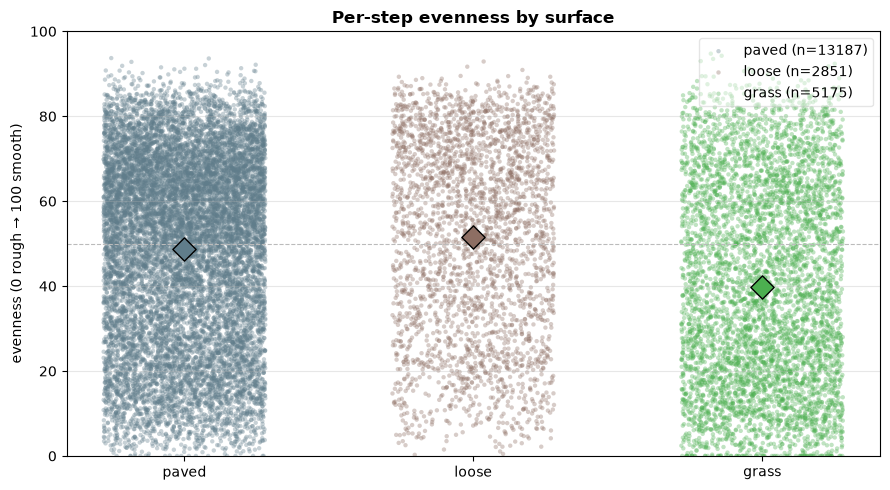

In [55]:
if len(V):
    order = [s for s in ['paved','loose','grass'] if s in V['surf'].unique()]
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(9, 5))
    for i, s in enumerate(order):
        vv = V.loc[V['surf'] == s, 'evenness'].values
        x = i + rng.uniform(-0.28, 0.28, size=len(vv))
        ax.scatter(x, vv, s=10, alpha=0.35, color=SURF_COLORS.get(s, '#888'), edgecolors='none', label=f'{s} (n={len(vv)})')
        ax.scatter([i],[vv.mean()], s=140, marker='D', color=SURF_COLORS.get(s,'#888'),
                   edgecolors='black', zorder=5)   # mean diamond
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
    ax.set_ylim(0,100); ax.axhline(50, color='#bbb', ls='--', lw=.8)
    ax.set_ylabel('evenness (0 rough → 100 smooth)'); ax.set_title('Per-step evenness by surface', fontweight='bold')
    ax.legend(loc='upper right', framealpha=.5); ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.savefig(os.path.join(CHARTS_DIR,f'evenness_points_by_surface{SUF}.png'), dpi=140, bbox_inches='tight'); plt.show()
else:
    print('No surface labels available — run §7 first (needs recordings with surface tags).')

## 9. Evenness distributions by surface

Overlaid histograms (left) and violins (right) of the evenness score per surface — two views of how the classes separate.

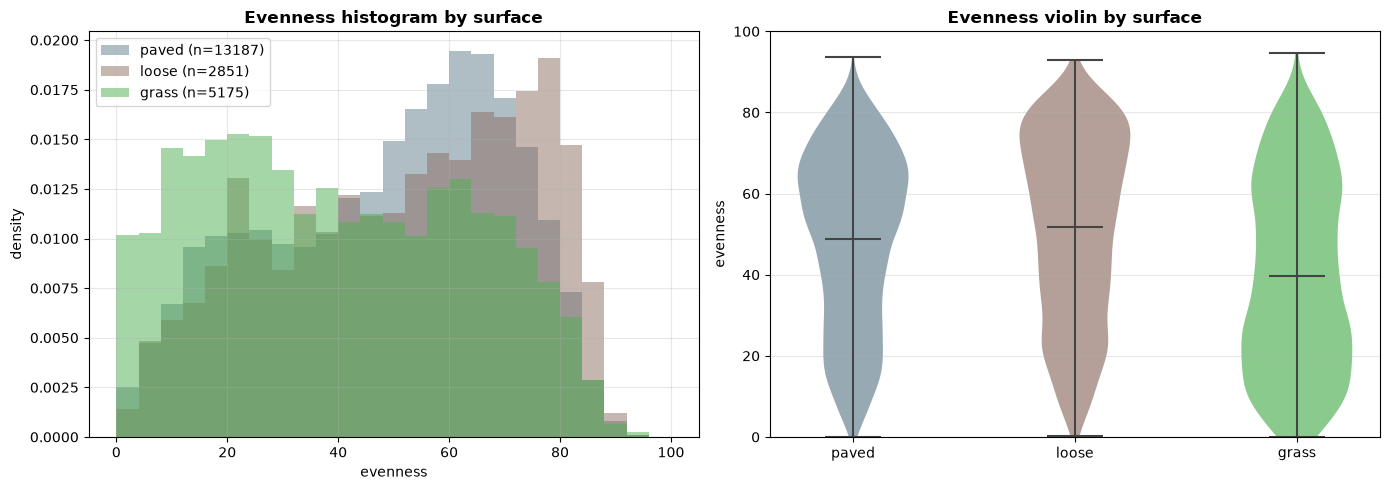

       mean  median   std  count
surf                            
grass  39.7    37.8  23.6   5175
loose  51.6    54.9  22.8   2851
paved  48.8    52.4  21.6  13187


In [56]:
if len(V):
    order = [s for s in ['paved','loose','grass'] if s in V['surf'].unique()]
    data = [V.loc[V['surf']==s,'evenness'].values for s in order]
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    # (a) overlaid histograms (density) per surface
    bins = np.linspace(0, 100, 26)
    for s, d in zip(order, data):
        ax[0].hist(d, bins=bins, density=True, alpha=0.5, color=SURF_COLORS.get(s,'#888'), label=f'{s} (n={len(d)})')
    ax[0].set_title('Evenness histogram by surface', fontweight='bold')
    ax[0].set_xlabel('evenness'); ax[0].set_ylabel('density'); ax[0].legend(); ax[0].grid(alpha=.3)
    # (b) violin plot per surface
    parts = ax[1].violinplot(data, showmeans=True, showextrema=True)
    for pc, s in zip(parts['bodies'], order):
        pc.set_facecolor(SURF_COLORS.get(s,'#888')); pc.set_alpha(0.65)
    for key in ('cmeans','cmaxes','cmins','cbars'):
        if key in parts: parts[key].set_color('#444')
    ax[1].set_xticks(range(1, len(order)+1)); ax[1].set_xticklabels(order)
    ax[1].set_ylim(0,100); ax[1].set_ylabel('evenness'); ax[1].set_title('Evenness violin by surface', fontweight='bold'); ax[1].grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.savefig(os.path.join(CHARTS_DIR,f'evenness_dist_by_surface{SUF}.png'), dpi=140, bbox_inches='tight'); plt.show()
    print(V.groupby('surf')['evenness'].agg(['mean','median','std','count']).round(1).to_string())
else:
    print('No surface labels available — run §7 first (needs recordings with surface tags).')

## 10. Per-walk analysis — how even, and how variable

Scores every step of each walk with the fitted scaler, then summarises each route two ways: **how even it is overall** (mean/median evenness) and **how variable the evenness is along it** (std, IQR, coefficient of variation), plus the share of rough vs smooth steps. Set `WALKS_GLOB` to the recordings you want treated as walks.

Also reports, for each walk, the **share of its steps in each surface class** — the
classes from `SMAP`, plus `transition` for steps touching a transition/wait region or
straddling two surfaces, and `unlabelled` for untagged stretches. These shares are over
every step the walk produced, including the ones the fitting gate would discard, so they
sum to 100 and tell you what the walk was actually made of. `dominant_surface` names the
largest share.

In [57]:
# ---- per-step surface class, for the share columns ----------------------------
# Classes come from SMAP, so this follows whichever surface scheme the notebook is set
# to. Two extra buckets: 'transition' for steps touching a transition/wait region, and
# 'unlabelled' for steps in a recording with no tags, or outside every tagged region.
SURF_CLASSES = sorted(set(SMAP.values())) + ['transition', 'unlabelled']


def step_surfaces(csv_path):
    """-> DataFrame[foot, order, surface] for every step the extractor produces.

    For recordings in the fitted set this agrees with steps['surface'] by construction,
    since both come from _step_kept(). It is recomputed here because this function also
    runs on NEW recordings that are not in the fitted set.

    Uses step_windows() so the 'order' index matches extract_steps exactly under either
    segmentation, and _step_kept()'s rules so the classification agrees with section 2.
    """
    raw = pd.read_csv(csv_path, low_memory=False)
    if 'sole_id' not in raw.columns:
        return pd.DataFrame(columns=['foot', 'order', 'surface'])
    soles = list(raw['sole_id'].dropna().unique())
    pairs = [(s, ('right' if str(s) in ('1', '1.0') else
                  'left' if str(s) in ('2', '2.0') else f'sole{s}')) for s in soles]
    rows = []
    for sole, foot in (pairs or [(1, 'right'), (2, 'left')]):
        sub = raw[raw['sole_id'] == sole].reset_index(drop=True)
        if len(sub) < MIN_DP:
            continue
        P = sub[ALL_SENSORS].apply(pd.to_numeric, errors='coerce').fillna(0).values
        tot = P.sum(1)
        ts = pd.to_numeric(sub['timestamp'], errors='coerce').values \
            if 'timestamp' in sub.columns else np.arange(len(sub))
        ev = contact_events(csv_path, sole) if SEGMENTATION == 'events' else None
        st_, en_ = step_windows(tot, ts, ev)
        surf = _row_surface_labels(sub)
        order = 0
        for i in range(len(st_)):
            a, b = int(st_[i]), int(en_[i]); n = b - a
            if n < MIN_DP or n > MAX_DP:
                continue            # mirror extract_steps' filter so 'order' aligns
            if surf is None:
                lab = 'unlabelled'
            else:
                ws = list(surf[a:b])
                present = [v for v in ws if v is not None]
                if any(v == EXCLUDE_LABEL for v in ws):
                    lab = 'transition'
                elif not present:
                    lab = 'unlabelled'
                elif len(set(present)) > 1:
                    lab = 'transition'          # straddles two surfaces
                elif len(present) < TRANSITION_MIN_LABELED_FRAC * len(ws):
                    lab = 'transition'          # only partly inside one surface
                else:
                    lab = present[0]
            rows.append(dict(foot=foot, order=order, surface=lab))
            order += 1
    return pd.DataFrame(rows)


# recordings to analyse as individual walks (default: the fitting set; point at GPS walks if you prefer)
WALKS_GLOB = RAW_GLOB
ROUGH_THR, SMOOTH_THR = 35, 65      # evenness below/above these = a rough / smooth step

files = sorted(glob.glob(WALKS_GLOB, recursive=True))
print(f'WALKS_GLOB = {WALKS_GLOB!r}  ->  {len(files)} file(s)')
walk_rows = []; errs = 0
for f in files:
    try:
        r = score_recording(f)
    except Exception as ex:
        if errs < 3: print(f'  [skip] {os.path.basename(f)}: {ex}')
        errs += 1; continue
    if not len(r):
        if errs < 3: print(f'  [skip] {os.path.basename(f)}: 0 steps extracted'); errs += 1
        continue
    e = r['evenness'].values; n = len(e)
    row = dict(
        walk=os.path.basename(f), n_steps=n,
        mean_evenness=float(np.mean(e)), median_evenness=float(np.median(e)),
        std_evenness=float(np.std(e)),                             # variability (absolute)
        iqr_evenness=float(np.subtract(*np.percentile(e,[75,25]))),
        cv_evenness=float(np.std(e)/(np.mean(e)+1e-9)),            # variability (relative)
        p10=float(np.percentile(e,10)), p90=float(np.percentile(e,90)),
        pct_rough=float(100*np.mean(e<ROUGH_THR)), pct_smooth=float(100*np.mean(e>SMOOTH_THR)))
    # share of this walk's steps in each surface class (sums to 100 across the classes)
    try:
        sf = step_surfaces(f)
    except Exception as ex:
        sf = pd.DataFrame(columns=['foot','order','surface'])
        if errs < 3: print(f'  [surface] {os.path.basename(f)}: {ex}')
    if len(sf):
        share = sf['surface'].value_counts(normalize=True) * 100
        row['n_steps_surf'] = int(len(sf))
        for cls in SURF_CLASSES:
            row[f'pct_{cls}'] = float(share.get(cls, 0.0))
        row['dominant_surface'] = str(share.idxmax())
    else:
        row['n_steps_surf'] = 0
        for cls in SURF_CLASSES:
            row[f'pct_{cls}'] = float('nan')
        row['dominant_surface'] = 'unknown'
    walk_rows.append(row)
if not walk_rows:
    raise ValueError(f'No walks scored from {len(files)} file(s) matched by WALKS_GLOB={WALKS_GLOB!r}. '
                     'Check the recordings have sole_id / pressure_01..12 / accel_* / gyro_* columns, '
                     'or point WALKS_GLOB at the right folder.')
walks = pd.DataFrame(walk_rows).sort_values('mean_evenness').reset_index(drop=True)
walks.to_csv(os.path.join(CHARTS_DIR,f'evenness_by_walk{SUF}.csv'), index=False)
print(f'{len(walks)} walks analysed -> evenness_by_walk{SUF}.csv')
print(walks[['walk','n_steps','mean_evenness','median_evenness','std_evenness',
             'cv_evenness','pct_rough','pct_smooth']].round(1).to_string(index=False))

_pct = [f'pct_{c}' for c in SURF_CLASSES if f'pct_{c}' in walks.columns]
print('\nshare of each walk\'s steps by surface class (%):')
print(walks[['walk','n_steps_surf']+_pct+['dominant_surface']].round(1).to_string(index=False))
_mismatch = walks[walks['n_steps_surf'] != walks['n_steps']]
if len(_mismatch):
    print(f'\n[check] {len(_mismatch)} walk(s) where the surface pass and the scoring pass '
          'disagree on the step count - the shares for those rows are over a different '
          'set of steps than the evenness stats:')
    print(_mismatch[['walk','n_steps','n_steps_surf']].to_string(index=False))

WALKS_GLOB = 'c:\\Users\\Sam\\WalkSensePlace\\Individual Users\\**\\*.csv'  ->  78 file(s)
78 walks analysed -> evenness_by_walk_3class_events.csv
                   walk  n_steps  mean_evenness  median_evenness  std_evenness  cv_evenness  pct_rough  pct_smooth
REC_20260514_174319.csv      211           17.3             16.0          11.7          0.7       94.8         0.9
REC_20260519_154547.csv      179           17.6             15.1          13.1          0.7       91.6         1.1
REC_20260515_154900.csv      313           17.9             15.7          12.6          0.7       93.0         0.6
REC_20260519_155015.csv      497           18.7             16.8          12.7          0.7       88.1         0.4
REC_20260515_155937.csv      339           19.2             16.3          13.7          0.7       88.5         0.9
REC_20260817_171138.csv      296           20.1             17.6          13.9          0.7       89.2         0.7
REC_20260514_173910.csv      186           20.4 

## 11. Per-walk plots

Routes ranked by evenness (bar = mean, whisker = ±1 std variability), the full per-walk distribution (box), and evenness-vs-variability (does a rougher route also swing more?).

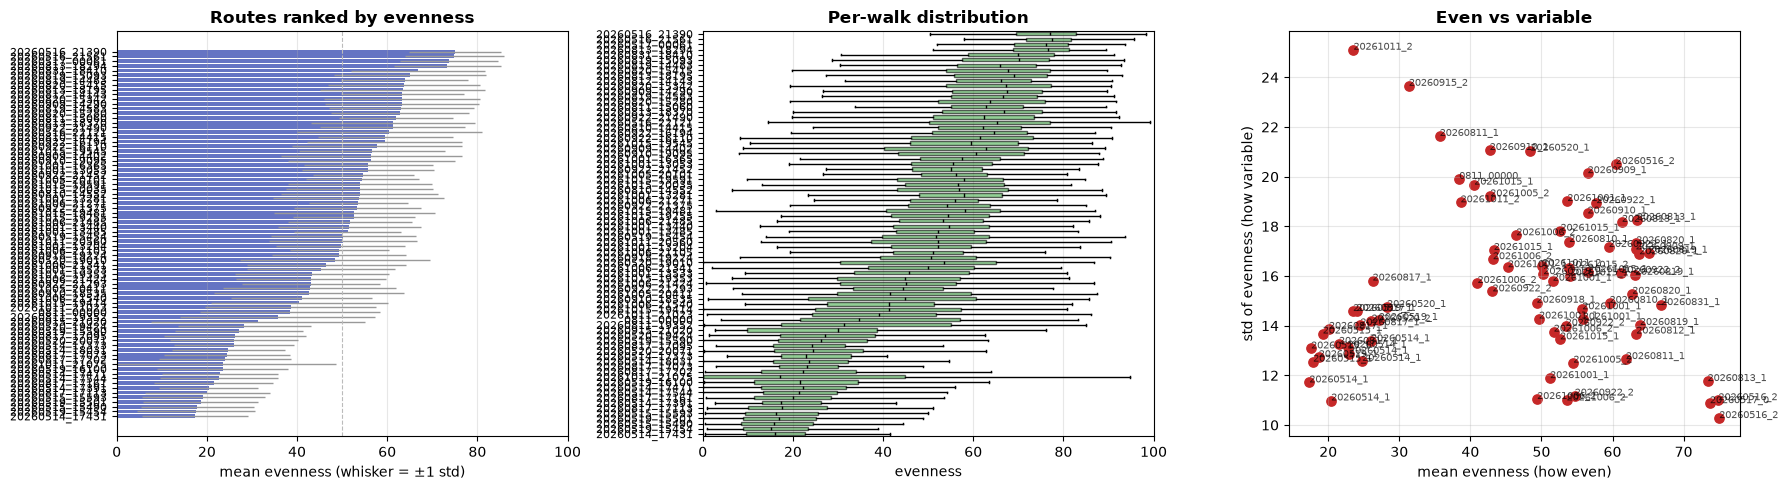

In [58]:
if len(walks):
    # per-walk step distributions, in the same (even-ascending) order as `walks`
    per = {os.path.basename(f): score_recording(f)['evenness'].values
           for f in sorted(glob.glob(WALKS_GLOB, recursive=True))
           if os.path.basename(f) in set(walks['walk'])}
    order = list(walks['walk']); short = [w.replace('REC_','').replace('.csv','')[:14] for w in order]

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    # (1) ranked mean +/- std
    m = walks['mean_evenness'].values; sd = walks['std_evenness'].values
    ax[0].barh(range(len(order)), m, xerr=sd, color='#3F51B5', alpha=.8, error_kw=dict(ecolor='#999', lw=1))
    ax[0].set_yticks(range(len(order))); ax[0].set_yticklabels(short, fontsize=8)
    ax[0].axvline(50, color='#bbb', ls='--', lw=.8); ax[0].set_xlim(0,100)
    ax[0].set_xlabel('mean evenness (whisker = ±1 std)'); ax[0].set_title('Routes ranked by evenness', fontweight='bold'); ax[0].grid(axis='x', alpha=.3)
    # (2) per-walk distributions
    data = [per[w] for w in order]
    bp = ax[1].boxplot(data, vert=False, patch_artist=True, showfliers=False, widths=.6)
    for b in bp['boxes']: b.set_facecolor('#4CAF50'); b.set_alpha(.6)
    for med in bp['medians']: med.set_color('black')
    ax[1].set_yticks(range(1,len(order)+1)); ax[1].set_yticklabels(short, fontsize=8)
    ax[1].set_xlim(0,100); ax[1].set_xlabel('evenness'); ax[1].set_title('Per-walk distribution', fontweight='bold'); ax[1].grid(axis='x', alpha=.3)
    # (3) even vs variable
    ax[2].scatter(walks['mean_evenness'], walks['std_evenness'], s=45, color='#C62828')
    for _,r in walks.iterrows():
        ax[2].annotate(r['walk'].replace('REC_','')[:10], (r['mean_evenness'], r['std_evenness']), fontsize=7, alpha=.7)
    ax[2].set_xlabel('mean evenness (how even)'); ax[2].set_ylabel('std of evenness (how variable)')
    ax[2].set_title('Even vs variable', fontweight='bold'); ax[2].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(os.path.join(CHARTS_DIR,f'evenness_by_walk{SUF}.png'), dpi=140, bbox_inches='tight'); plt.show()
else:
    print('No walks analysed — check WALKS_GLOB.')